In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [14]:
df = pd.read_csv('raw_sales.csv')
df.head()

,datesold,postcode,price,propertyType,bedrooms
0,2007-02-07 00:00:00,2607,525000,house,4
1,2007-02-27 00:00:00,2906,290000,house,3
2,2007-03-07 00:00:00,2905,328000,house,3
3,2007-03-09 00:00:00,2905,380000,house,4
4,2007-03-21 00:00:00,2906,310000,house,3


In [15]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 29580 entries, 0 to 29579
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   datesold      29580 non-null  str  
 1   postcode      29580 non-null  int64
 2   price         29580 non-null  int64
 3   propertyType  29580 non-null  str  
 4   bedrooms      29580 non-null  int64
dtypes: int64(3), str(2)
memory usage: 1.1 MB


In [16]:
df['datesold'] = pd.to_datetime(df['datesold'])

In [17]:
df['datesold'].min(),df['datesold'].max()

(Timestamp('2007-02-07 00:00:00'), Timestamp('2019-07-27 00:00:00'))

In [18]:
df = df.sort_values('datesold')

In [19]:
monthly_price = (df.set_index('datesold').resample('ME').agg({
    'price' : 'mean',
    'bedrooms' : 'mean'
}))
monthly_price.head()

,price,bedrooms
datesold,,
2007-02-28,407500.000000,3.500000
2007-03-31,339333.333333,3.333333
2007-04-30,798000.000000,3.666667
2007-05-31,339500.000000,3.000000
2007-06-30,520333.333333,3.333333


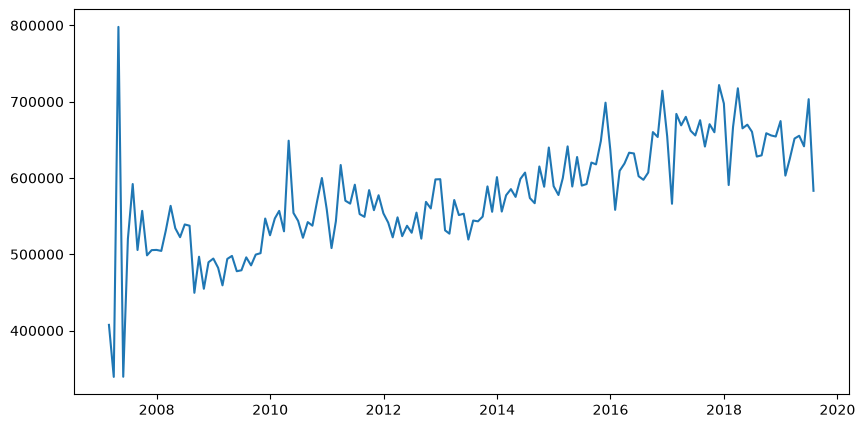

In [20]:
plt.figure(figsize=(10,5))
plt.plot(monthly_price['price'])
plt.show()

In [21]:
monthly_df = monthly_price.copy()
monthly_df['month'] = monthly_df.index.month
monthly_df['year'] = monthly_df.index.year
monthly_df['bedrooms'] = monthly_df['bedrooms'].round()

In [22]:
property_ratio = (df.assign(month=df['datesold'].dt.to_period('M'))
                  .groupby(['month','propertyType'])
                  .size()
                  .groupby(level=0)
                  .transform(lambda x: x/x.sum())
                  .unstack(fill_value=0))
property_ratio

propertyType,house,unit
month,,
2007-02,1.000000,0.000000
2007-03,1.000000,0.000000
2007-04,1.000000,0.000000
2007-05,1.000000,0.000000
2007-06,0.833333,0.166667
...,...,...
2019-03,0.750000,0.250000
2019-04,0.740566,0.259434
2019-05,0.763636,0.236364


In [23]:
property_ratio.index = property_ratio.index.to_timestamp('M')
property_ratio.head()

propertyType,house,unit
month,,
2007-02-28,1.000000,0.000000
2007-03-31,1.000000,0.000000
2007-04-30,1.000000,0.000000
2007-05-31,1.000000,0.000000
2007-06-30,0.833333,0.166667


In [24]:
monthly_df = monthly_df.join(property_ratio)
monthly_df.head()

,price,bedrooms,month,year,house,unit
datesold,,,,,,
2007-02-28,407500.000000,4.0,2,2007,1.000000,0.000000
2007-03-31,339333.333333,3.0,3,2007,1.000000,0.000000
2007-04-30,798000.000000,4.0,4,2007,1.000000,0.000000
2007-05-31,339500.000000,3.0,5,2007,1.000000,0.000000
2007-06-30,520333.333333,3.0,6,2007,0.833333,0.166667


In [25]:
seasonality = monthly_df.groupby('month')['price'].mean()
seasonality

month
1     547216.241269
2     562260.963571
3     580561.178666
4     609383.360814
5     567881.538515
6     579990.826833
7     572996.112723
8     555060.213201
9     584590.302302
10    578211.656047
11    608506.812903
12    590819.529244
Name: price, dtype: float64

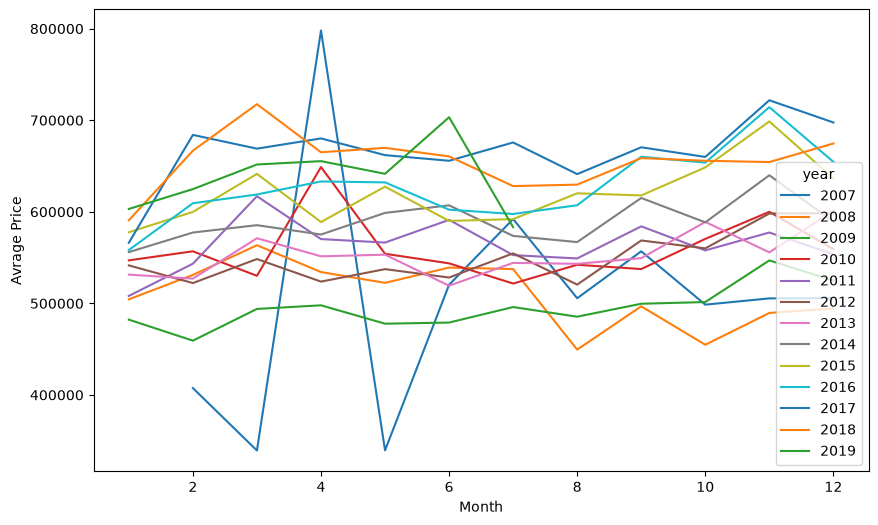

In [26]:
pivot = monthly_df.pivot(index='month',columns='year',values='price')

pivot.plot(figsize=(10,6))
plt.xlabel('Month')
plt.ylabel('Avrage Price')
plt.show()

In [27]:
monthly_df['time'] = range(len(monthly_df))
monthly_df

,price,bedrooms,month,year,house,unit,time
datesold,,,,,,,
2007-02-28,407500.000000,4.0,2,2007,1.000000,0.000000,0
2007-03-31,339333.333333,3.0,3,2007,1.000000,0.000000,1
2007-04-30,798000.000000,4.0,4,2007,1.000000,0.000000,2
2007-05-31,339500.000000,3.0,5,2007,1.000000,0.000000,3
2007-06-30,520333.333333,3.0,6,2007,0.833333,0.166667,4
...,...,...,...,...,...,...,...
2019-03-31,651666.737288,3.0,3,2019,0.750000,0.250000,145
2019-04-30,655325.561321,3.0,4,2019,0.740566,0.259434,146
2019-05-31,641491.136364,3.0,5,2019,0.763636,0.236364,147


In [28]:
monthly_model = pd.get_dummies(monthly_df,drop_first=True,columns=['month'],dtype=int)
monthly_model.head()

,price,bedrooms,year,house,unit,time,month_2,month_3,month_4,month_5,month_6,month_7,month_8,month_9,month_10,month_11,month_12
datesold,,,,,,,,,,,,,,,,,
2007-02-28,407500.000000,4.0,2007,1.000000,0.000000,0,1,0,0,0,0,0,0,0,0,0,0
2007-03-31,339333.333333,3.0,2007,1.000000,0.000000,1,0,1,0,0,0,0,0,0,0,0,0
2007-04-30,798000.000000,4.0,2007,1.000000,0.000000,2,0,0,1,0,0,0,0,0,0,0,0
2007-05-31,339500.000000,3.0,2007,1.000000,0.000000,3,0,0,0,1,0,0,0,0,0,0,0
2007-06-30,520333.333333,3.0,2007,0.833333,0.166667,4,0,0,0,0,1,0,0,0,0,0,0


In [29]:
split_index = int((len(monthly_model)*.7))
train = monthly_model.iloc[:split_index]
test = monthly_model.iloc[split_index:]

In [30]:
X_train = train[['time']]
X_test = test[['time']]
y_train = train['price']
y_test = test['price']

In [31]:
from sklearn.linear_model import LinearRegression

# Model training only with trend
model = LinearRegression()
model.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[1076.21]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['time']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,4.919e+05
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [32]:
y_pred = model.predict(X_test)

In [33]:
from sklearn.metrics import mean_absolute_error,root_mean_squared_error,r2_score
mae_trend = mean_absolute_error(y_test,y_pred)
rmse_trend = root_mean_squared_error(y_test,y_pred)
r2_trend = r2_score(y_test,y_pred)
print('MAE trend: ',mae_trend)
print('RMSE trend : ',rmse_trend)
print('R2 trend : ',r2_trend)

MAE trend:  35406.0407185472
RMSE trend :  43119.26932859757
R2 trend :  -0.29745795338788716


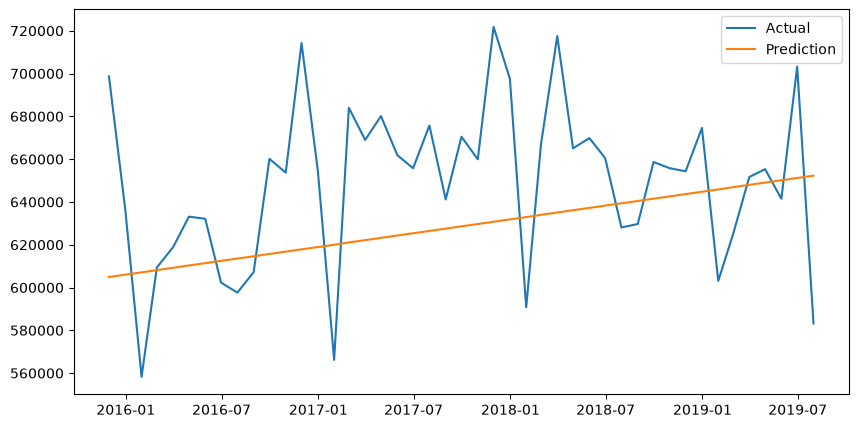

In [34]:
plt.figure(figsize=(10,5))
plt.plot(y_test.index,y_test,label='Actual')
plt.plot(y_test.index,y_pred,label='Prediction')
plt.legend()
plt.show()

In [35]:
print('Train')
print(train.index.min(),':',train.index.max())
print('Test')
print(test.index.min(),':',test.index.max())

Train
2007-02-28 00:00:00 : 2015-10-31 00:00:00
Test
2015-11-30 00:00:00 : 2019-07-31 00:00:00


In [36]:
X_train = train.drop(columns=['price','bedrooms','unit','house'])
X_test = test.drop(columns=['price','bedrooms','unit','house'])
y_train = train['price']
y_test = test['price']

In [37]:
# Model training with trends and seasonality (Dummy Encoding)
model = LinearRegression()
model.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](13,)","[-25646.82, 3216.59, -2830.56,..., -1380.3 , 13871.27, -144.27]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](13,)","['year','time','month_2',...,'month_10','month_11','month_12']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,5.195e+07
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,13
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(12)


In [38]:
y_pred = model.predict(X_test)

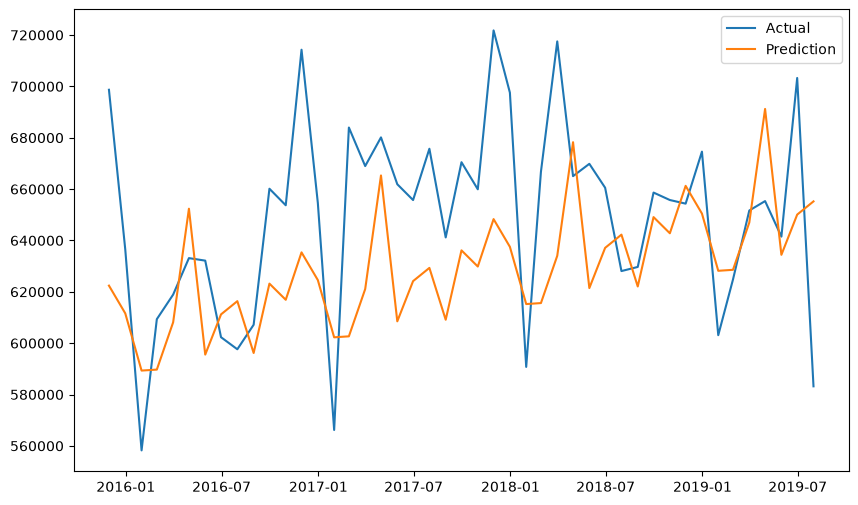

In [39]:
plt.figure(figsize=(10,6))
plt.plot(y_test.index,y_test,label='Actual')
plt.plot(y_test.index,y_pred,label='Prediction')
plt.legend()
plt.show()

In [40]:
from sklearn.metrics import mean_absolute_error,root_mean_squared_error,r2_score
mae_trend_seasonality_dummy = mean_absolute_error(y_test,y_pred)
rmse_trend_seasonality_dummy = root_mean_squared_error(y_test,y_pred)
r2_trend_seasonality_dummy = r2_score(y_test,y_pred)
print('MAE trend_seasonality_dummy : ',mae_trend_seasonality_dummy)
print('RMSE trend_seasonality_dummy : ',rmse_trend_seasonality_dummy)
print('R2 trend_seasonality_dummy : ',r2_trend_seasonality_dummy)

MAE trend_seasonality_dummy :  33389.33260785337
RMSE trend_seasonality_dummy :  40270.7069562042
R2 trend_seasonality_dummy :  -0.13169400215526905


In [41]:
monthly_df['sin_12'] = np.sin(2 * np.pi * monthly_df['time'] / 12)
monthly_df['cos_12'] = np.cos(2 * np.pi * monthly_df['time'] / 12)
monthly_df.head()

,price,bedrooms,month,year,house,unit,time,sin_12,cos_12
datesold,,,,,,,,,
2007-02-28,407500.000000,4.0,2,2007,1.000000,0.000000,0,0.000000,1.000000e+00
2007-03-31,339333.333333,3.0,3,2007,1.000000,0.000000,1,0.500000,8.660254e-01
2007-04-30,798000.000000,4.0,4,2007,1.000000,0.000000,2,0.866025,5.000000e-01
2007-05-31,339500.000000,3.0,5,2007,1.000000,0.000000,3,1.000000,6.123234e-17
2007-06-30,520333.333333,3.0,6,2007,0.833333,0.166667,4,0.866025,-5.000000e-01


In [42]:
split_index = int(len(monthly_df)*.7)
train = monthly_df.iloc[:split_index]
test = monthly_df.iloc[split_index:]

In [43]:
X_train = train.drop(columns=['price','bedrooms','month','unit','house'])
X_test = test.drop(columns=['price','bedrooms','month','unit','house'])
y_train = train['price']
y_test = test['price']

In [44]:
# Model training with trend and seasonality(cyclic(sin/cos) Encoding)
model = LinearRegression()
model.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](4,)","[-48640.18, 5133.87, 11580.33, 11046.5 ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](4,)","['year','time','sin_12','cos_12']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,9.809e+07
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(4)


In [45]:
y_pred = model.predict(X_test)

mae_trend_seasonality_cyclic = mean_absolute_error(y_test,y_pred)
rmse_trend_seasonality_cyclic = root_mean_squared_error(y_test,y_pred)
r2_trend_seasonality_cyclic = r2_score(y_test,y_pred)
print('MAE trend_seasonality_cyclic : ',mae_trend_seasonality_cyclic)
print('RMSE trend_seasonality_cyclic : ',rmse_trend_seasonality_cyclic)
print('R2 trend_seasonality_cyclic : ',r2_trend_seasonality_cyclic)

MAE trend_seasonality_cyclic :  31045.809471664248
RMSE trend_seasonality_cyclic :  39191.85860793881
R2 trend_seasonality_cyclic :  -0.07187027178239314


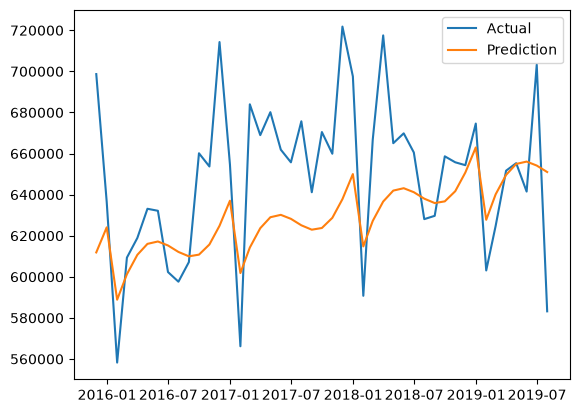

In [46]:
plt.plot(y_test.index,y_test,label='Actual')
plt.plot(y_test.index,y_pred,label='Prediction')
plt.legend()
plt.show()

In [47]:
monthly_df['price_lag_1'] = monthly_df['price'].shift(1)
monthly_df['price_lag_12'] = monthly_df['price'].shift(12)
monthly_df = monthly_df.dropna()

In [48]:
monthly_df.head()

,price,bedrooms,month,year,house,unit,time,sin_12,cos_12,price_lag_1,price_lag_12
datesold,,,,,,,,,,,
2008-02-29,531080.000000,4.0,2,2008,1.000000,0.000000,12,-2.449294e-16,1.000000e+00,504428.571429,407500.000000
2008-03-31,563500.000000,3.0,3,2008,0.833333,0.166667,13,5.000000e-01,8.660254e-01,531080.000000,339333.333333
2008-04-30,534204.545455,4.0,4,2008,0.954545,0.045455,14,8.660254e-01,5.000000e-01,563500.000000,798000.000000
2008-05-31,522394.736842,3.0,5,2008,0.947368,0.052632,15,1.000000e+00,1.194340e-15,534204.545455,339500.000000
2008-06-30,539092.647059,3.0,6,2008,0.941176,0.058824,16,8.660254e-01,-5.000000e-01,522394.736842,520333.333333


In [49]:
split_index = int(len(monthly_df)*.7)
train = monthly_df.iloc[:split_index]
test = monthly_df.iloc[split_index:]

In [50]:
X_train = train.drop(columns=['price','month'])
X_test = test.drop(columns=['price','month'])
y_train = train['price']
y_test = test['price']

In [51]:
# Model training with all feature (cyclic(sin/cos))
model = LinearRegression()
model.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](9,)","[ 39341.15,-48511.27, 7247.33,..., 12902.48, 0.27, -0.07]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](9,)","['bedrooms','year','house',...,'cos_12','price_lag_1','price_lag_12']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,9.76e+07
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,9
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(7)


In [52]:
y_pred = model.predict(X_test)

mae_all_feature = mean_absolute_error(y_test,y_pred)
rmse_all_feature = root_mean_squared_error(y_test,y_pred)
r2_all_feature = r2_score(y_test,y_pred)
print('MAE all_feature : ',mae_all_feature)
print('RMSE all_feature : ',rmse_all_feature)
print('R2 all_feature : ',r2_all_feature)

MAE all_feature :  26715.200450453252
RMSE all_feature :  35896.78663497034
R2 all_feature :  -0.010042776622885885


In [53]:
coeff = pd.Series(
    model.coef_,
    index=X_train.columns
)
print(coeff.sort_values(ascending=False))

bedrooms        39341.148237
cos_12          12902.483250
sin_12           8461.213318
house            7247.325192
time             5030.131440
price_lag_1         0.271458
price_lag_12       -0.066816
unit            -7247.325192
year           -48511.270839
dtype: float64


Baseline Model

In [54]:
y_pred_naive = y_test.index.map(lambda date: monthly_df.loc[monthly_df.index < date,'price'].iloc[-1])
mae_baseline = mean_absolute_error(y_test,y_pred_naive)
rmse_baseline = root_mean_squared_error(y_test,y_pred_naive)
r2_baseline = r2_score(y_test,y_pred_naive)
print('Baseline MAE',mae_baseline)
print('Baseline RMSE',rmse_baseline)
print('Baseline R2',r2_baseline)

Baseline MAE 34382.10642491198
Baseline RMSE 47071.54677265933
Baseline R2 -0.7367829968387041


In [55]:
results = pd.DataFrame({
    'Model' : [
        'BaseLine',
        'Trend',
        'Trend + Seasonality (dummy encoding)',
        'Trend + Seasonality (cyclic encoding)',
        'Trend + Seasonality + Lag + All Features'
    ],
    'MAE' : [
        mae_baseline,
        mae_trend,
        mae_trend_seasonality_dummy,
        mae_trend_seasonality_cyclic,
        mae_all_feature
    ],
    'RMSE' : [
        rmse_baseline,
        rmse_trend,
        rmse_trend_seasonality_dummy,
        rmse_trend_seasonality_cyclic,
        rmse_all_feature
    ],
    'R2' : [
        r2_baseline,
        r2_trend,
        r2_trend_seasonality_dummy,
        r2_trend_seasonality_cyclic,
        r2_all_feature
    ]

}).set_index('Model')
results

,MAE,RMSE,R2
Model,,,
BaseLine,34382.106425,47071.546773,-0.736783
Trend,35406.040719,43119.269329,-0.297458
Trend + Seasonality (dummy encoding),33389.332608,40270.706956,-0.131694
Trend + Seasonality (cyclic encoding),31045.809472,39191.858608,-0.071870
Trend + Seasonality + Lag + All Features,26715.200450,35896.786635,-0.010043


Forcasting

In [56]:
forcast_df = monthly_df.copy()
forcast_df['target'] = forcast_df['price'].shift(-1)

In [57]:
forcast_df = forcast_df.dropna()

In [63]:
X = forcast_df.drop(columns=['target','month'])
y = forcast_df['target']

In [64]:
split_index = int(len(forcast_df)*.7)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

In [65]:
model = LinearRegression()
model.fit(X_train,y_train)

y_pred = model.predict(X_test)

In [66]:
print(root_mean_squared_error(y_test,y_pred))
print(mean_absolute_error(y_test,y_pred))
print(r2_score(y_test,y_pred))

35235.64305594822
26589.217744538382
0.026820339768305557


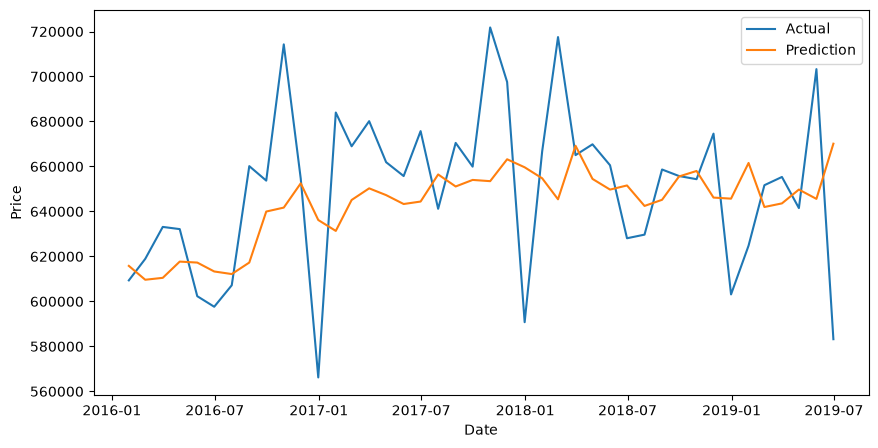

In [67]:
plt.figure(figsize=(10,5))
plt.plot(y_test.index,y_test,label='Actual')
plt.plot(y_test.index,y_pred,label='Prediction')
plt.legend()
plt.xlabel('Date')
plt.ylabel('Price')
plt.show()